# Inspect the model

In [ ]:
import os
import sys
import random
import numpy as np # type: ignore
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
import mrcnn.model as modellib
from mrcnn import utils # type: ignore
from mrcnn import visualize
from mrcnn.model import log

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'Python'))
from utils import ShrubConfig, ShrubDataset

In [ ]:
%matplotlib inline 

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT_DIR, "logs")

# Directory with train data
TRAIN_DIR = os.path.join(ROOT_DIR, "JuniperMapper", "Photo_Interpretation_Data")

# Local path to trained weights file
COCO_MODEL_PATH = os.path.join(ROOT_DIR, "mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

In [2]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

In [9]:
# Training dataset
dataset_train = ShrubDataset()
dataset_train.load_dataset(
    os.path.join(TRAIN_DIR, "Train", "Images"),
    os.path.join(TRAIN_DIR, "Train", "masks_points.json")
)
dataset_train.prepare()

# Validation dataset
dataset_val = ShrubDataset()
dataset_val.load_dataset(
    os.path.join(TRAIN_DIR, "Test", "Images"),
    os.path.join(TRAIN_DIR, "Test", "masks_points.json")
)
dataset_val.prepare()

In [3]:
class InferenceConfig(ShrubConfig):
    GPU_COUNT = 1
    IMAGES_PER_GPU = 1

inference_config = InferenceConfig()
inference_config.display()


Configurations:
BACKBONE                       resnet50
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     1
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        100
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 1
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  1024
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  800
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [1024 1024    3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.001
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE          

In [4]:
# Recreate the model in inference mode
model = modellib.MaskRCNN(mode="inference", 
                          config=inference_config,
                          model_dir=MODEL_DIR)

# Get path to saved weights
# Either set a specific path or find last trained weights
# model_path = os.path.join(ROOT_DIR, ".h5 file name here")
model_path = model.find_last()

# Load trained weights
print("Loading weights from ", model_path)
model.load_weights(model_path, by_name=True)

Loading weights from  C:\Trabajos_CIranzo\Segmentacion\logs\shrubs_cfg\mask_rcnn_shrubs_cfg_0020.h5


Include a random image from the validation set. Load the ground reference values.

original_image           shape: (1024, 1024, 3)       min:    0.00000  max:  189.00000  uint8
image_meta               shape: (14,)                 min:    1.00000  max: 1024.00000  float64
gt_class_id              shape: (11,)                 min:    1.00000  max:    1.00000  int32
gt_bbox                  shape: (11, 4)               min:  112.00000  max:  911.00000  int32
gt_mask                  shape: (1024, 1024, 11)      min:    0.00000  max:    1.00000  uint8


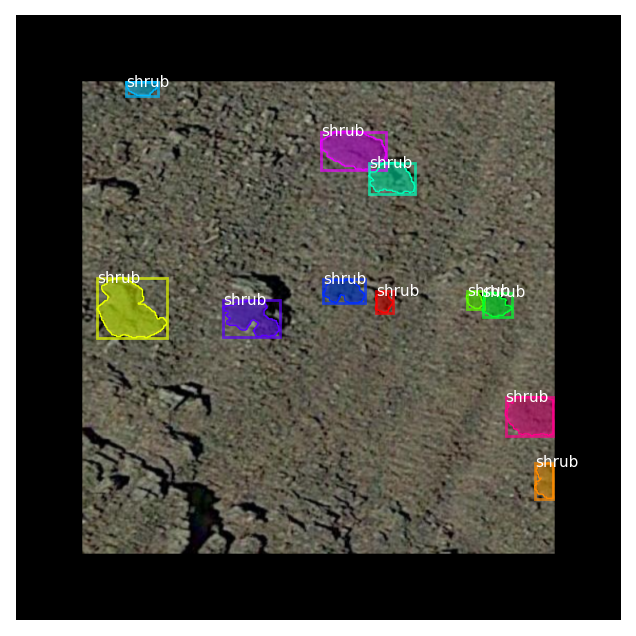

In [10]:
# Test on a random image
image_id = random.choice(dataset_val.image_ids)
original_image, image_meta, gt_class_id, gt_bbox, gt_mask =\
    modellib.load_image_gt(dataset_val, inference_config, 
                           image_id, use_mini_mask=False)

log("original_image", original_image)
log("image_meta", image_meta)
log("gt_class_id", gt_class_id)
log("gt_bbox", gt_bbox)
log("gt_mask", gt_mask)

visualize.display_instances(original_image, gt_bbox, gt_mask, gt_class_id, 
                            dataset_train.class_names, figsize=(8, 8))

Now ingest the image to the model and display the predictions.

Processing 1 images
image                    shape: (1024, 1024, 3)       min:    0.00000  max:  189.00000  uint8
molded_images            shape: (1, 1024, 1024, 3)    min: -123.70000  max:   72.20000  float64
image_metas              shape: (1, 14)               min:    0.00000  max: 1024.00000  int32
anchors                  shape: (1, 261888, 4)        min:   -0.35390  max:    1.29134  float32


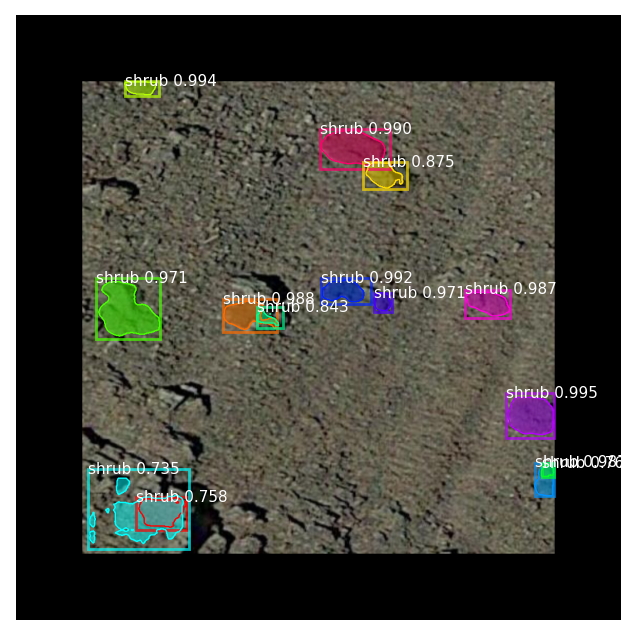

In [11]:
results = model.detect([original_image], verbose=1)

r = results[0]
visualize.display_instances(original_image, r['rois'], r['masks'], r['class_ids'], 
                            dataset_val.class_names, r['scores'], ax=get_ax())

## Evaluation

Mean Average Precision (mAP) is commonly used to analyze the performance of object detection and segmentation systems.

The mAP values are calculated over recall values from 0 to 1, based on the following sub metrics:

- Confusion Matrix
- Intersection over Union(IoU): indicates the overlap of the predicted bounding box coordinates to the ground truth box. Higher IoU indicates the predicted bounding box coordinates closely resembles the ground truth box coordinates.
- Recall: Measures how well you can find true positives(TP) out of all predictions(TP+FN).
- Precision: how well you can find true positives(TP) out of all positive predictions (TP+FP).

Average Precision (AP) is calculated as the weighted mean of precisions at each threshold; the weight is the increase in recall from the prior threshold.

Mean Average Precision is the average of AP of each class. However, the interpretation of AP and mAP varies in different contexts. For instance, in the evaluation document of the COCO object detection challenge, AP and mAP are the same.

Steps to calculate the AP:

- Generate the prediction scores using the model.
- Convert the prediction scores to class labels.
- Calculate the confusion matrix—TP, FP, TN, FN.
- Calculate the precision and recall metrics.
- Calculate the area under the precision-recall curve.
- Measure the average precision.

The mAP is calculated by finding Average Precision(AP) for each class and then average over a number of classes.

> mAP is the average of AP of each class. However, the interpretation of AP and mAP varies in different contexts. For instance, in the evaluation document of the COCO object detection challenge, AP and mAP are the same.

The mAP incorporates the trade-off between precision and recall and considers both false positives (FP) and false negatives (FN). This property makes mAP a suitable metric for most detection applications.

In [12]:
# Compute VOC-Style mAP @ IoU=0.5
# Running on 10 images. Increase for better accuracy.
image_ids = np.random.choice(dataset_val.image_ids, 10)
APs = []
for image_id in image_ids:
    # Load image and ground truth data
    image, image_meta, gt_class_id, gt_bbox, gt_mask =\
        modellib.load_image_gt(dataset_val, inference_config,
                               image_id, use_mini_mask=False)
    molded_images = np.expand_dims(modellib.mold_image(image, inference_config), 0)
    # Run object detection
    results = model.detect([image], verbose=0)
    r = results[0]
    # Compute AP
    AP, precisions, recalls, overlaps =\
        utils.compute_ap(gt_bbox, gt_class_id, gt_mask,
                         r["rois"], r["class_ids"], r["scores"], r['masks'])
    APs.append(AP)
    
print("mAP: ", np.mean(APs))



mAP:  0.8566094607509305


## Precision-Recall

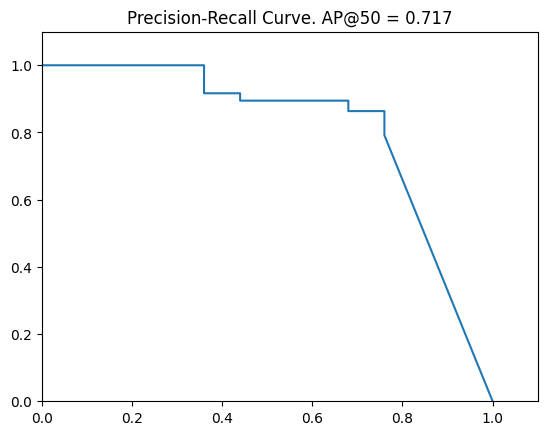

In [18]:
# Draw precision-recall curve
AP, precisions, recalls, overlaps = utils.compute_ap(gt_bbox, gt_class_id, gt_mask,
                                          r['rois'], r['class_ids'], r['scores'], r['masks'])
visualize.plot_precision_recall(AP, precisions, recalls)

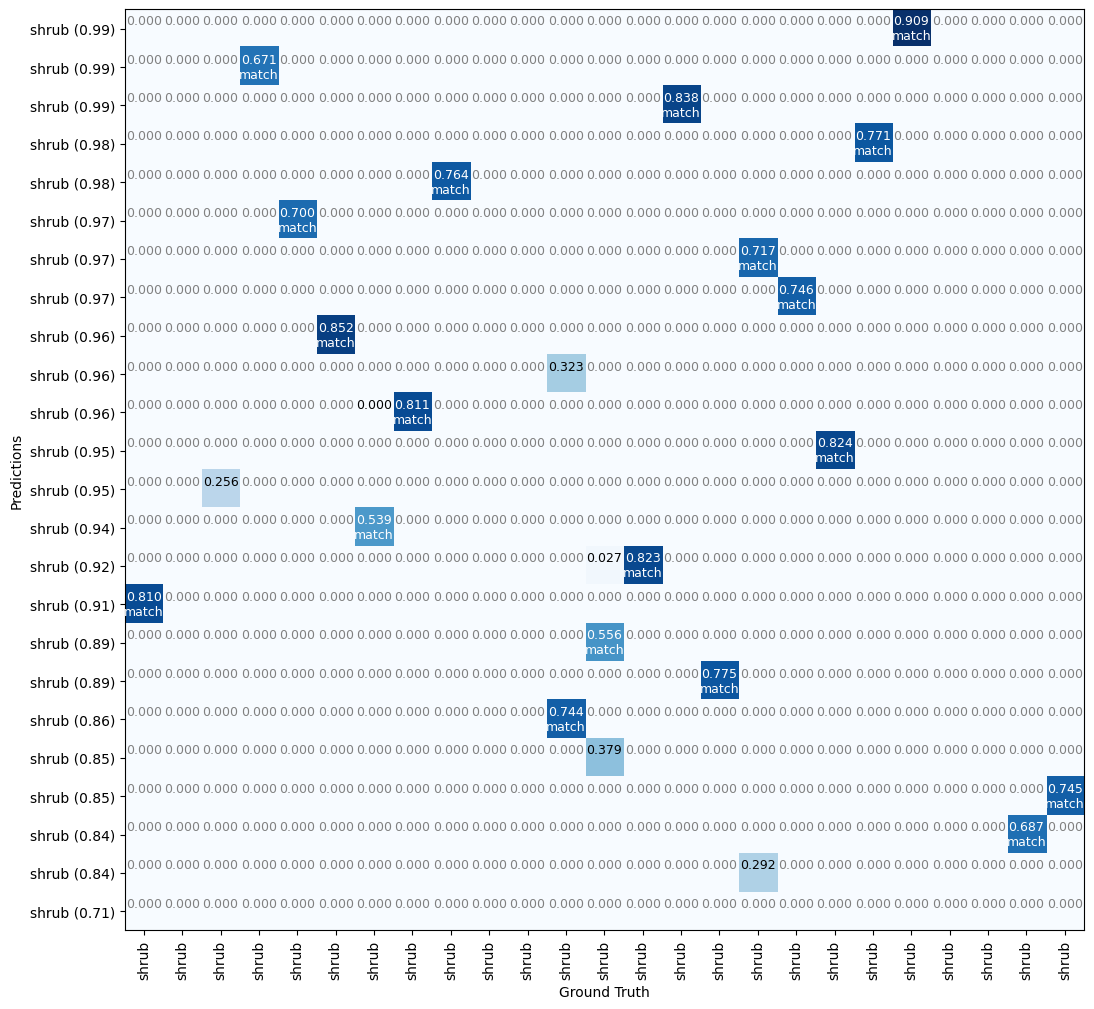

In [20]:
# Grid of ground truth objects and their predictions
visualize.plot_overlaps(gt_class_id, r['class_ids'], r['scores'],
                        overlaps, dataset_train.class_names)

## Compute mAP @ IoU=50 on Batch of Images

In [21]:
# Compute VOC-style Average Precision
def compute_batch_ap(image_ids):
    APs = []
    for image_id in image_ids:
        # Load image
        image, image_meta, gt_class_id, gt_bbox, gt_mask =\
            modellib.load_image_gt(dataset_val, inference_config,
                                   image_id, use_mini_mask=False)
        # Run object detection
        results = model.detect([image], verbose=0)
        # Compute AP
        r = results[0]
        AP, precisions, recalls, overlaps =\
            utils.compute_ap(gt_bbox, gt_class_id, gt_mask,
                              r['rois'], r['class_ids'], r['scores'], r['masks'])
        APs.append(AP)
    return APs

# Pick a set of random images
image_ids = np.random.choice(dataset_val.image_ids, 10)
APs = compute_batch_ap(image_ids)
print("mAP @ IoU=50: ", np.mean(APs))

mAP @ IoU=50:  0.7967189698995967


## Review Weight Stats

In [ ]:
# Show stats of all trainable weights 
visualize.display_weight_stats(model)

## Histograms of Weights

In [ ]:
# Pick layer types to display
LAYER_TYPES = ['Conv2D']
# More examples: 'Dense', 'Conv2DTranspose'
# Get layers
layers = model.get_trainable_layers()
layers = list(filter(lambda l: l.__class__.__name__ in LAYER_TYPES, 
                layers))

# Display Histograms
fig, ax = plt.subplots(len(layers), 2, figsize=(10, 3*len(layers)),
                       gridspec_kw={"hspace":1})
for l, layer in enumerate(layers):
    weights = layer.get_weights()
    for w, weight in enumerate(weights):
        tensor = layer.weights[w]
        ax[l, w].set_title(tensor.name)
        _ = ax[l, w].hist(weight[w].flatten(), 50)

## TODO: Step by Step Prediction

https://github.com/ahmedfgad/Mask-RCNN-TF2/blob/master/samples/coco/inspect_model.ipynb